In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 6021
DATA = Path("..") / "data" / "processed"

OUTCOME_NAMES = {1: "died", 2: "passed chamber", 3: "law"}

pd.set_option("display.max_columns", 50)

# Loading Data + Checking Data

In [2]:
df = pd.read_csv(DATA / "model_ready_billz.csv")
print(df.shape)

missing = df.isna().sum()
print("missing values: \n", missing[missing > 0].to_string() or "none")

(45641, 31)
missing values: 
 Series([], )


In [3]:
counts = df.groupby(["congress", "outcome"]).size().unstack(fill_value=0)
shares = counts.div(counts.sum(axis=1), axis=0).round(3)
display(counts)
display(shares)

outcome,1,2,3
congress,,,
116,12958,730,340
117,14120,641,357
118,15538,685,272


outcome,1,2,3
congress,,,
116,0.924,0.052,0.024
117,0.934,0.042,0.024
118,0.942,0.042,0.016


# Feature Lists

In [4]:
TARGET = "outcome"

NUM = [
    "n_original_cosponsors", "days_left_in_congress",
    "nominate_dim1", "nominate_dim2", "abs_nominate_dim1",
    "seniority", "vote_share", "delegation_size", "lagged_les"
]

CAT = ["type", "origin_chamber", "sponsor_party", "policy_area"]

BIN = [
    "commemorative", "sponsor_majority", "freshman", "chair", "subchair",
    "power_cmte", "maj_leader", "min_leader", "state_leg", "lagged_les_missing"
]

# identifiers
DROP = [
    "bill_id", "congress", "introduced_date", "title",
    "sponsor_bioguide_id", "sponsor_state", "icpsr"
]

FEATURES = NUM + CAT + BIN



# Time split:

Training on 116-117 and holding out 118. groups_train to keep each sponsor's bills in a single CV fold

In [7]:
TRAIN_CONGRESSES = [116, 117]
TEST_CONGRESS = 118

train = df[df['congress'].isin(TRAIN_CONGRESSES).reset_index(drop=True)]
test = df[df['congress'] == TEST_CONGRESS].reset_index(drop=True)

X_train, y_train = train[FEATURES], train[TARGET]
groups_train = train['sponsor_bioguide_id']

X_test, y_test = test[FEATURES], test[TARGET]

print("train:", X_train.shape, "| test:", X_test.shape)
print("sponsors in train:", groups_train.nunique())

train: (29146, 23) | test: (16495, 23)
sponsors in train: 623


# preprocessing

In [8]:
prep = ColumnTransformer(
    [

    ("num", StandardScaler(), NUM),
    # rare policy areas (<20 train bills) pooled into one "infrequent" column
    # categories never seen in training will map there too instead of erroring
    # claude used to figure that out ^
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT),
    ("bin", "passthrough", BIN)
    ],
    remainder="drop",
)

# cv setup

In [10]:
N_SPLITS = 5
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
# check that every validation fold has enough of each class (especialy 3 = law)
fold_counts = pd.DataFrame(
    {f"fold {i}": y_train.iloc[val].value_counts().sort_index()
     for i, (_, val) in enumerate(cv.split(X_train, y_train, groups_train))}
).rename(index=OUTCOME_NAMES)
fold_counts

,fold 0,fold 1,fold 2,fold 3,fold 4
outcome,,,,,
died,5416,5415,5416,5416,5415
passed chamber,273,273,277,274,274
law,136,145,138,137,141


#### above fold_counts check was Claude generated - explaining it to myself here

cv.split(X_train, y_train, groups_train) returns  a generator that makes 5 pairs (one per fold) of training indices and validation indices. y_train passed so splitter can stratify based on class, groups_train so it can keep sponsors together, X-train used for number of rows.

enumerate(...) attaches a counter like (0, (train_index, val_index)) and then for i, (_, val) unpacks them with i being the fold number, _ throwing away training indices, and val keeping validation indices.

y_train.iloc[val] selects outcome of bills in validation fold

.value_counts().sort_index() gives a Series like {1: 1197, 2: 241, 3: 166} and then sort_index reorders it by label so each fold lists classes in same order

the dict comprehension builds {"fold 0": Series, "fold 1": Series} which is then built into dataframe with rows renamed to class names

# model eval function

In [15]:
SCORING = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "acc": "accuracy"}

results = []

def evaluate(name, model, notes=""): # clone to give each model it's own copy of the pipeline
    pipe = Pipeline([("prep", clone(prep)), ("clf", model)])
    scores = cross_validate( # fit clone on four folds, score on 5th
        pipe, X_train, y_train, groups=groups_train,
        cv=cv, scoring=SCORING, n_jobs=-1, # -1 runs jobs in parallel across CPU cores
    )
    # scores will be a dict of arrays containing fit time, score time, test_f1, test_bal_acc, and acc

    row = {"model": name, "notes": notes}

    for metric in SCORING:
        s = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = round(s.mean(), 4)
        row[f"{metric}_std"] = round(s.std(), 4)
    row['fit_sec'] = round(scores['fit_time'].mean(), 2)

    results[:] = [r for r in results if r["model"] != name] # results[:] replaces contents of existing global results list in place
    # list comprehension removes any row with same name
    results.append(row)
    return pipe

def show_results(sort_by="f1_macro_mean"):
    # turn list of dicts into dataframe
    return pd.DataFrame(results).sort_values(sort_by, ascending=False).reset_index(drop=True)

# baseline models

In [16]:
evaluate("dummy_majority", DummyClassifier(strategy='most_frequent'),
         notes="always predicts died")

evaluate("dummy_stratified", DummyClassifier(strategy="stratified", random_state=SEED),
         notes="random guesses at class rates")

logit = evaluate(
    "logit_l2_balanced",
    LogisticRegression(class_weight="balanced", max_iter=2000),
    notes="L2, C=1, class_weight=balanced"
)
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,logit_l2_balanced,"L2, C=1, class_weight=balanced",0.3508,0.0111,0.5690,0.0145,0.5972,0.0217,0.86
1,dummy_stratified,random guesses at class rates,0.3359,0.0085,0.3360,0.0085,0.8653,0.0021,0.20
2,dummy_majority,always predicts died,0.3211,0.0001,0.3333,0.0000,0.9290,0.0005,0.20


                precision    recall  f1-score   support

          died       0.97      0.60      0.74     27078
passed chamber       0.11      0.59      0.18      1371
           law       0.08      0.52      0.13       697

      accuracy                           0.60     29146
     macro avg       0.38      0.57      0.35     29146
  weighted avg       0.91      0.60      0.70     29146



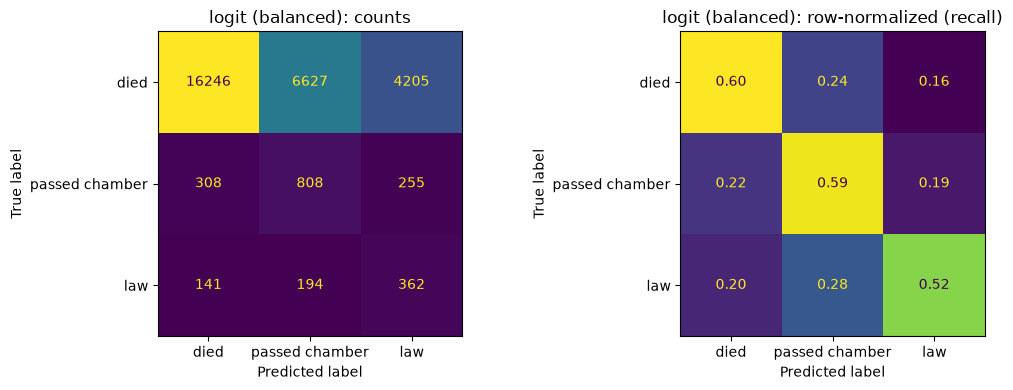

In [20]:
oof_pred = cross_val_predict(logit, X_train, y_train, groups=groups_train, cv=cv)
labels = sorted(OUTCOME_NAMES)

print(classification_report(
    y_train, oof_pred, labels=labels,
    target_names=[OUTCOME_NAMES[k] for k in labels], zero_division=0,

))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, norm, title in zip(axes, [None, "true"], ['counts', 'row-normalized (recall)']):
    ConfusionMatrixDisplay.from_predictions(
        y_train, oof_pred, labels=labels, normalize=norm, 
        display_labels=[OUTCOME_NAMES[k] for k in labels],
        values_format=".2f" if norm else "d", ax=ax, colorbar=False,
    )
    ax.set_title(f"logit (balanced): {title}")
plt.tight_layout()

In [19]:
evaluate("logit_l2_unweighted", LogisticRegression(max_iter=2000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outp

In [21]:
df["lagged_les_missing"].value_counts()

lagged_les_missing
0    40238
1     5403
Name: count, dtype: int64